# CVA of a 10-year interest rate swap

A short walkthrough of the project. The full analysis is in `scripts/` and the report in `report/`.
Every number comes from the saved FRED snapshot in `data/raw/` (US Treasury curve of 17 November 2026).

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import matplotlib.pyplot as plt
from src.data import valuation_inputs
from src.curve import bootstrap_treasury_curve
from src.hull_white import HullWhite
from src.swap import Swap, par_swap_rate
from src.exposure import time_grid, simulate_values, exposure_profiles, collateralised_values
from src.cva import cva, hazard_from_spread

## 1. Today's zero curve
Treasury par yields from FRED, bootstrapped into discount factors.

In [2]:
inputs = valuation_inputs()
curve = bootstrap_treasury_curve(inputs["maturities"], inputs["par_yields"])
print("valuation date:", inputs["date"])
for t in [1, 2, 5, 10, 30]:
    print(f"{t:>2}y zero rate: {curve.zero_rate(t):.3%}")

valuation date: 2026-11-17
 1y zero rate: 4.550%
 2y zero rate: 4.750%
 5y zero rate: 4.850%
10y zero rate: 5.073%
30y zero rate: 5.477%


## 2. Hull-White model
`a` and `sigma` come from `scripts/02_curve_and_calibration.py` (fit to 3 years of historical
zero-yield volatility). The model is fitted exactly to today's curve.

In [3]:
calibration = json.loads((ROOT / "results" / "calibration.json").read_text())
a, sigma = calibration["hull_white"]["a"], calibration["hull_white"]["sigma"]
model = HullWhite(a, sigma, curve)
print(f"a = {a:.4f}, sigma = {sigma * 1e4:.0f} bp per year")

a = 0.0118, sigma = 91 bp per year


## 3. The trade: pay fixed on USD 100 million for 10 years, at the par rate
At the par rate the swap is worth exactly 0 today.

In [4]:
rate = par_swap_rate(curve, 0, 10)
swap = Swap(100e6, rate, 0, 10, payer=True)
print(f"par rate {rate:.3%}, value today {swap.value(curve):.2f} USD")

par rate 5.100%, value today 0.00 USD


## 4. Simulate 20,000 rate paths and value the swap every two weeks

In [5]:
times = time_grid(10, 26)
sim = simulate_values(model, [swap], times, 20_000, seed=2026)
values, deflator = sim["values"][0], sim["deflator"]
profile = exposure_profiles(values, deflator)
peak = profile["EE"].argmax()
print(f"peak EE  {profile['EE'][peak] / 1e6:.2f}m at {times[peak]:.1f} years")
print(f"peak PFE {profile['PFE'].max() / 1e6:.2f}m (97.5% quantile)")

peak EE  4.59m at 4.5 years
peak PFE 19.09m (97.5% quantile)


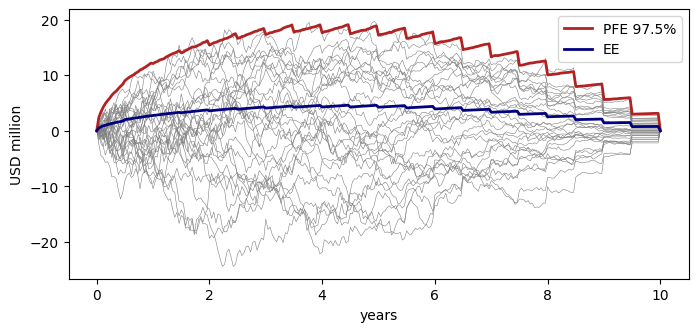

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(times, values[:, :30] / 1e6, color="grey", lw=0.4)
ax.plot(times, profile["PFE"] / 1e6, color="firebrick", lw=2, label="PFE 97.5%")
ax.plot(times, profile["EE"] / 1e6, color="navy", lw=2, label="EE")
ax.set_xlabel("years"); ax.set_ylabel("USD million"); ax.legend();

## 5. CVA: what we lose on average if the counterparty defaults
Hazard rate = BBB credit spread / LGD (credit triangle), LGD = 60%.

In [7]:
spread = inputs["spreads"]["counterparty_BBB"]
hazard = hazard_from_spread(spread, 0.6)
value = cva(times, profile["EE_discounted"], hazard, 0.6)
print(f"BBB spread {spread:.2%} -> hazard {hazard:.2%} a year")
print(f"CVA = {value:,.0f} USD = {value / 100e6 * 1e4:.1f} bp of notional")

BBB spread 1.15% -> hazard 1.92% a year
CVA = 262,344 USD = 26.2 bp of notional


## 6. Check against a closed form
At a reset date T, the discounted EE is exactly the price of a payer swaption expiring at T.

In [8]:
for T in [2.0, 5.0, 8.0]:
    i = np.argmin(abs(times - T))
    closed = model.swaption(T, swap.pay_times[swap.pay_times > T + 1e-9], rate, 100e6)
    print(f"T = {T}: Monte Carlo {profile['EE_discounted'][i] / 1e6:.3f}m, Jamshidian {closed / 1e6:.3f}m")

T = 2.0: Monte Carlo 3.220m, Jamshidian 3.224m
T = 5.0: Monte Carlo 3.149m, Jamshidian 3.138m
T = 8.0: Monte Carlo 1.514m, Jamshidian 1.503m


## 7. Collateral: a CSA with zero threshold and a 10-business-day margin period of risk

In [9]:
collateralised = collateralised_values(values, threshold=0.0, mpr_steps=1)
value_csa = cva(times, exposure_profiles(collateralised, deflator)["EE_discounted"], hazard, 0.6)
print(f"CVA with CSA: {value_csa:,.0f} USD ({value_csa / value:.0%} of the uncollateralised CVA)")

CVA with CSA: 26,951 USD (10% of the uncollateralised CVA)


## 8. Wrong-way risk
See `scripts/05_wrong_way_risk.py`: when the counterparty's default intensity rises with rates,
the payer swap's CVA rises (the exposure is largest exactly when default is most likely).

In [10]:
wwr = json.loads((ROOT / "results" / "wrong_way_risk.json").read_text())
for row in wwr["rows"]:
    if row["eta"] == wwr["eta_base"]:
        print(f"rho {row['rho']:+.1f}: payer CVA x{row['payer_vs_independent']:.2f}, receiver x{row['receiver_vs_independent']:.2f}")

rho -0.9: payer CVA x0.43, receiver x2.17
rho -0.6: payer CVA x0.59, receiver x1.72
rho -0.3: payer CVA x0.78, receiver x1.33
rho +0.0: payer CVA x1.01, receiver x1.00
rho +0.3: payer CVA x1.26, receiver x0.73
rho +0.6: payer CVA x1.55, receiver x0.52
rho +0.9: payer CVA x1.85, receiver x0.36
